In [118]:
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
import numpy as np
from scipy.stats import zscore
import math

In [119]:
# Download latest version
#path = kagglehub.dataset_download("kumarajarshi/life-expectancy-who")
path = "/root/.cache/kagglehub/datasets/kumarajarshi/life-expectancy-who/versions/1/Life Expectancy Data.csv"

In [120]:
df = pd.read_csv(path,sep=",")

In [121]:
# Configura o pandas para exibir todas as colunas do DataFrame
pd.set_option('display.max_columns', None)

## Diagnostico e Perfilamento

In [122]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   object 
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   object 
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10   BMI                             2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio               

In [123]:
df = df.rename(
    columns={
        'Country': 'nmPais',
        'Year': 'ano',
        'Status': 'status',
        'Life expectancy ': 'expectativaVida',
        'Adult Mortality': 'mortalidadeAdultos',
        'infant deaths': 'mortesInfantis',
        'Alcohol': 'consumoAlcool',
        'percentage expenditure': 'percentualGastos',
        'Hepatitis B': 'hepatiteB',
        'Measles ': 'sarampo',
        ' BMI ': 'imc',
        'under-five deaths ': 'mortesMenores5Anos',
        'Polio': 'polio',
        'Total expenditure': 'gastoTotalSaude',
        'Diphtheria ': 'difteria',
        ' HIV/AIDS': 'hivAids',
        'GDP': 'pib',
        'Population': 'populacao',
        ' thinness  1-19 years': 'magreza1a19Anos',
        ' thinness 5-9 years': 'magreza5a9Anos',
        'Income composition of resources': 'composicaoRendaRecursos',
        'Schooling': 'escolaridade'
    }
)

display(df.head())

,nmPais,ano,status,expectativaVida,mortalidadeAdultos,mortesInfantis,consumoAlcool,percentualGastos,hepatiteB,sarampo,imc,mortesMenores5Anos,polio,gastoTotalSaude,difteria,hivAids,pib,populacao,magreza1a19Anos,magreza5a9Anos,composicaoRendaRecursos,escolaridade
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,19.1,83,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,18.6,86,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,18.1,89,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,17.6,93,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,17.2,97,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [124]:
df.describe()

,ano,expectativaVida,mortalidadeAdultos,mortesInfantis,consumoAlcool,percentualGastos,hepatiteB,sarampo,imc,mortesMenores5Anos,polio,gastoTotalSaude,difteria,hivAids,pib,populacao,magreza1a19Anos,magreza5a9Anos,composicaoRendaRecursos,escolaridade
count,2938.000000,2928.000000,2928.000000,2938.000000,2744.000000,2938.000000,2385.000000,2938.000000,2904.000000,2938.000000,2919.000000,2712.00000,2919.000000,2938.000000,2490.000000,2.286000e+03,2904.000000,2904.000000,2771.000000,2775.000000
mean,2007.518720,69.224932,164.796448,30.303948,4.602861,738.251295,80.940461,2419.592240,38.321247,42.035739,82.550188,5.93819,82.324084,1.742103,7483.158469,1.275338e+07,4.839704,4.870317,0.627551,11.992793
std,4.613841,9.523867,124.292079,117.926501,4.052413,1987.914858,25.070016,11467.272489,20.044034,160.445548,23.428046,2.49832,23.716912,5.077785,14270.169342,6.101210e+07,4.420195,4.508882,0.210904,3.358920
min,2000.000000,36.300000,1.000000,0.000000,0.010000,0.000000,1.000000,0.000000,1.000000,0.000000,3.000000,0.37000,2.000000,0.100000,1.681350,3.400000e+01,0.100000,0.100000,0.000000,0.000000
25%,2004.000000,63.100000,74.000000,0.000000,0.877500,4.685343,77.000000,0.000000,19.300000,0.000000,78.000000,4.26000,78.000000,0.100000,463.935626,1.957932e+05,1.600000,1.500000,0.493000,10.100000
50%,2008.000000,72.100000,144.000000,3.000000,3.755000,64.912906,92.000000,17.000000,43.500000,4.000000,93.000000,5.75500,93.000000,0.100000,1766.947595,1.386542e+06,3.300000,3.300000,0.677000,12.300000
75%,2012.000000,75.700000,228.000000,22.000000,7.702500,441.534144,97.000000,360.250000,56.200000,28.000000,97.000000,7.49250,97.000000,0.800000,5910.806335,7.420359e+06,7.200000,7.200000,0.779000,14.300000
max,2015.000000,89.000000,723.000000,1800.000000,17.870000,19479.911610,99.000000,212183.000000,87.300000,2500.000000,99.000000,17.60000,99.000000,50.600000,119172.741800,1.293859e+09,27.700000,28.600000,0.948000,20.700000


In [125]:
# identificando valores nulos
df.isnull().sum()

,0
nmPais,0
ano,0
status,0
expectativaVida,10
mortalidadeAdultos,10
mortesInfantis,0
consumoAlcool,194
percentualGastos,0
hepatiteB,553
sarampo,0


# inicio transformacao

In [146]:
def mostraPerfilHistograma():
  # Seleciona apenas as colunas quantitativas (numéricas)
  colunas_numericas = df.select_dtypes(include=['float64', 'int64']).columns

  # Define o tamanho do grid de subplots
  num_colunas = len(colunas_numericas)
  cols_plot = 4
  rows_plot = math.ceil(num_colunas / cols_plot)

  fig, axes = plt.subplots(rows_plot, cols_plot, figsize=(20, 4 * rows_plot))
  axes = axes.flatten()

  for i, col in enumerate(colunas_numericas):
      # Remove valores nulos temporariamente apenas para a plotagem do histograma
      axes[i].hist(df[col].dropna(), bins=20, color='skyblue', edgecolor='black')
      axes[i].set_title(col, fontsize=12)
      axes[i].grid(True, linestyle='--', alpha=0.5)

  # Oculta subplots vazios caso o número de variáveis não seja múltiplo de cols_plot
  for j in range(i + 1, len(axes)):
      fig.delaxes(axes[j])

  plt.tight_layout()
  plt.show()

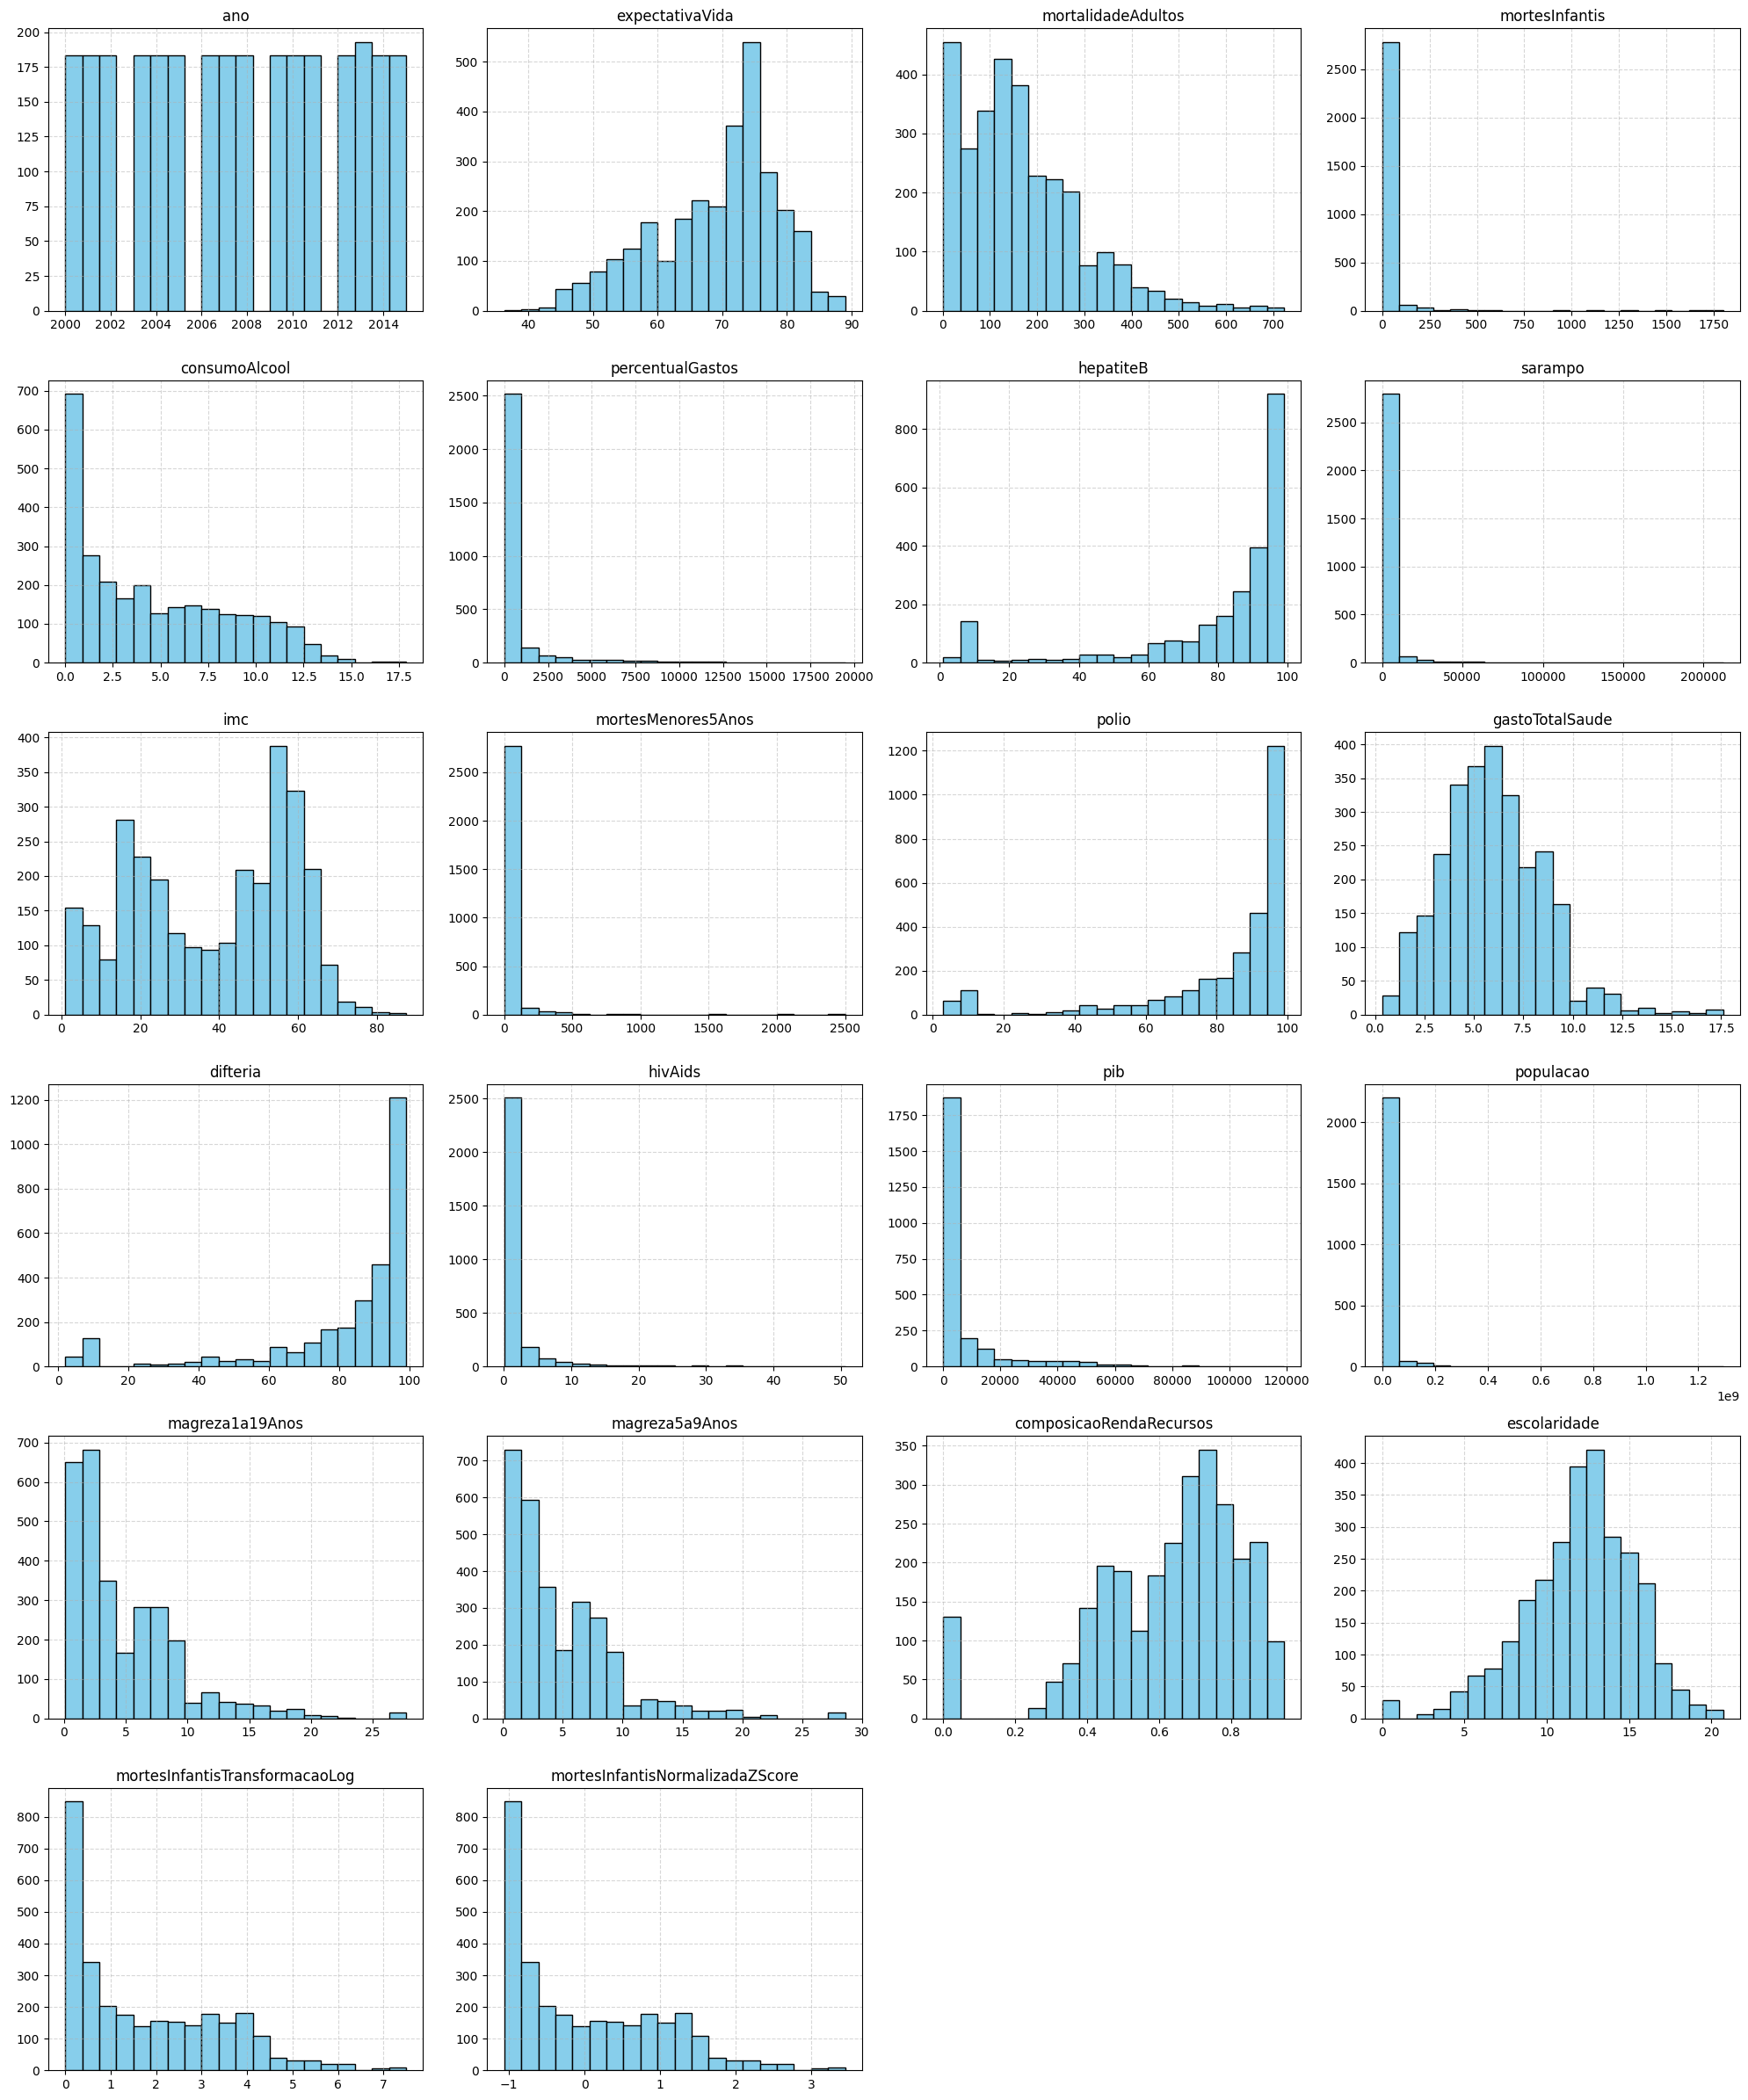

In [147]:
mostraPerfilHistograma()

In [157]:
#analise de registros nulos

df['percentual_nulos_por_linha'] = df.isnull().sum(axis=1) / len(df.columns) * 100
display(df[['nmPais', 'ano', 'percentual_nulos_por_linha']].head())

,nmPais,ano,percentual_nulos_por_linha
0,Afghanistan,2015,0.0
1,Afghanistan,2014,0.0
2,Afghanistan,2013,0.0
3,Afghanistan,2012,0.0
4,Afghanistan,2011,0.0


In [158]:
display(df.sort_values(by='percentual_nulos_por_linha', ascending=False).head(10))

,nmPais,ano,status,expectativaVida,mortalidadeAdultos,mortesInfantis,consumoAlcool,percentualGastos,hepatiteB,sarampo,imc,mortesMenores5Anos,polio,gastoTotalSaude,difteria,hivAids,pib,populacao,magreza1a19Anos,magreza5a9Anos,composicaoRendaRecursos,escolaridade,mortesInfantisTransformacaoLog,mortesInfantisNormalizadaZScore,percentual_nulos_por_linha
1715,Monaco,2013,Developing,NaN,NaN,0,0.01,0.0,99.0,0,NaN,0,99.0,4.3,99.0,0.1,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,-1.063659,37.500000
2423,South Sudan,2001,Developing,49.6,381.0,30,NaN,0.0,NaN,0,NaN,49,NaN,NaN,NaN,3.0,NaN,6974442.0,NaN,NaN,0.0,0.0,3.433987,1.001603,37.500000
2422,South Sudan,2002,Developing,52.0,382.0,30,NaN,0.0,NaN,0,NaN,48,NaN,NaN,NaN,3.3,NaN,7237276.0,NaN,NaN,0.0,0.0,3.433987,1.001603,37.500000
2421,South Sudan,2003,Developing,58.0,383.0,29,NaN,0.0,NaN,0,NaN,46,NaN,NaN,NaN,3.5,NaN,751642.0,NaN,NaN,0.0,0.0,3.401197,0.981883,37.500000
2420,South Sudan,2004,Developing,51.4,383.0,29,NaN,0.0,NaN,0,NaN,45,NaN,NaN,NaN,3.8,NaN,7787655.0,NaN,NaN,0.0,0.0,3.401197,0.981883,37.500000
2419,South Sudan,2005,Developing,51.9,383.0,28,NaN,0.0,NaN,0,NaN,44,NaN,NaN,NaN,3.9,NaN,818877.0,NaN,NaN,0.0,0.0,3.367296,0.961494,37.500000
2418,South Sudan,2006,Developing,52.5,383.0,28,NaN,0.0,NaN,0,NaN,43,NaN,NaN,NaN,4.1,NaN,8468152.0,NaN,NaN,0.0,0.0,3.367296,0.961494,37.500000
2417,South Sudan,2007,Developing,53.1,381.0,27,NaN,0.0,NaN,0,NaN,43,NaN,NaN,NaN,4.2,NaN,88568.0,NaN,NaN,0.0,0.0,3.332205,0.940389,37.500000
2424,South Sudan,2000,Developing,48.9,38.0,31,NaN,0.0,NaN,0,NaN,50,NaN,NaN,NaN,2.7,NaN,67656.0,NaN,NaN,0.0,0.0,3.465736,1.020697,37.500000
2416,South Sudan,2008,Developing,53.6,377.0,27,NaN,0.0,NaN,0,NaN,42,NaN,NaN,NaN,4.2,1678.711862,9263136.0,NaN,NaN,0.0,0.0,3.332205,0.940389,33.333333


In [159]:
problema_por_pais = df.groupby('nmPais')['percentual_nulos_por_linha'].mean().sort_values(ascending=False)
display(problema_por_pais.head(10))

,percentual_nulos_por_linha
nmPais,
Monaco,37.500000
San Marino,33.333333
South Sudan,31.770833
Niue,25.000000
Cook Islands,25.000000
Somalia,23.697917
Democratic People's Republic of Korea,21.875000
United Kingdom of Great Britain and Northern Ireland,21.093750
Democratic Republic of the Congo,19.010417


In [170]:
df[df['nmPais']=='Monaco']

,nmPais,ano,status,expectativaVida,mortalidadeAdultos,mortesInfantis,consumoAlcool,percentualGastos,hepatiteB,sarampo,imc,mortesMenores5Anos,polio,gastoTotalSaude,difteria,hivAids,pib,populacao,magreza1a19Anos,magreza5a9Anos,composicaoRendaRecursos,escolaridade,mortesInfantisTransformacaoLog,mortesInfantisNormalizadaZScore,percentual_nulos_por_linha
1715,Monaco,2013,Developing,NaN,NaN,0,0.01,0.0,99.0,0,NaN,0,99.0,4.3,99.0,0.1,NaN,NaN,NaN,NaN,NaN,NaN,0.0,-1.063659,37.5


In [169]:
print(df['ano'].unique())

array([2015, 2014, 2013, 2012, 2011, 2010, 2009, 2008, 2007, 2006, 2005,
       2004, 2003, 2002, 2001, 2000])

In [171]:
# Monaco so tem um registro e tem muitos valores nulos. E inconsistente para analise e sera excluido

df = df[df['nmPais'] != 'Monaco']

(array([2845.,   42.,   27.,    8.,    0.,    3.,    3.,    3.,    3.,
           4.]),
 array([   0.,  180.,  360.,  540.,  720.,  900., 1080., 1260., 1440.,
        1620., 1800.]),
 <BarContainer object of 10 artists>)

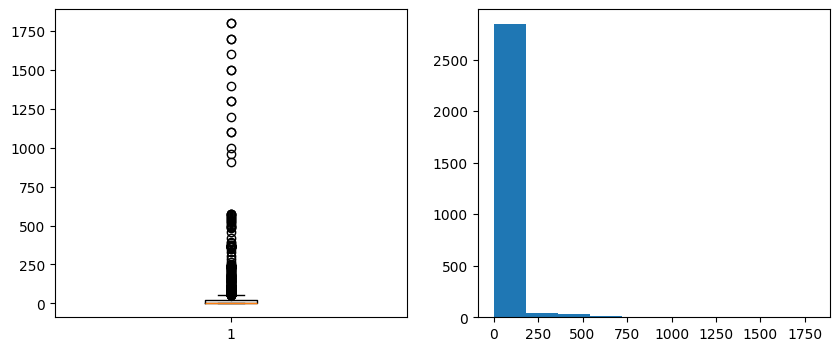

In [127]:
# analise da coluna de mortes infantis
morInf = df['mortesInfantis']
fig, axes = plt.subplots(1,2, figsize=(10,4))
axes[0].boxplot(morInf)
axes[1].hist(morInf)



In [154]:
#no histograma observei que há muitos valores abaixo de 250, e o eixo x pula de 0 a 250

'''
print((df['mortesInfantis']>250).sum())
print((df['mortesInfantis']<250).sum())
print((df['mortesInfantis']>1000).sum())
'''
#percebi que na verdade 58 valores estao acima de 250, enquanto 2880 valores estao abaixo de 250.
#isso significa que os valores acima de 250 sao valores extremos
#em 13 registros o numero de mortalidade infantil é maior que 1000. Isso nao faz sentido, tendo em vista que a definiçao do atributo é "Number of Infant Deaths per 1000 population"

df[df['mortesInfantis'] > 1000][['nmPais', 'ano', 'mortesInfantis']]

'''
Durante a análise exploratória, foram identificados 13 registros com valores superiores a 1.000 na variável mortesInfantis.
Inicialmente, esses valores poderiam ser considerados inconsistentes caso a variável representasse uma taxa por 1.000 habitantes.
Entretanto, os registros correspondem exclusivamente à Índia entre 2000 e 2012 e apresentam uma tendência temporal coerente,
indicando que os valores provavelmente representam o número absoluto de mortes infantis. Dessa forma, os registros foram mantidos na análise.
'''

df[df['mortesInfantis']==0].describe()

,ano,expectativaVida,mortalidadeAdultos,mortesInfantis,consumoAlcool,percentualGastos,hepatiteB,sarampo,imc,mortesMenores5Anos,polio,gastoTotalSaude,difteria,hivAids,pib,populacao,magreza1a19Anos,magreza5a9Anos,composicaoRendaRecursos,escolaridade,mortesInfantisTransformacaoLog,mortesInfantisNormalizadaZScore
count,848.000000,838.000000,838.000000,848.0,791.000000,848.000000,672.000000,848.000000,846.000000,848.000000,842.000000,790.000000,842.000000,848.000000,730.000000,5.920000e+02,846.000000,846.000000,825.000000,829.000000,848.0,8.480000e+02
mean,2007.850236,75.405131,106.306683,0.0,6.580885,1511.491841,86.382440,35.357311,48.238652,0.074292,90.709026,6.460861,89.856295,0.165920,14444.738721,1.509534e+06,2.850236,2.822813,0.720887,13.878166,0.0,-1.063659e+00
std,4.632922,5.048949,63.260288,0.0,4.443163,2982.305077,22.655283,172.587102,18.480163,0.262401,16.557819,2.629759,18.524580,0.224858,20079.081731,2.533360e+06,2.782833,2.807136,0.219768,2.865326,0.0,1.999581e-15
min,2000.000000,62.600000,1.000000,0.0,0.010000,0.000000,4.000000,0.000000,2.300000,0.000000,6.000000,1.120000,7.000000,0.100000,8.376432,3.400000e+01,0.100000,0.100000,0.000000,0.000000,0.0,-1.063659e+00
25%,2004.000000,72.200000,65.000000,0.0,1.950000,18.969334,88.000000,0.000000,41.125000,0.000000,92.000000,4.592500,92.000000,0.100000,1843.230182,4.820150e+04,0.900000,0.900000,0.692000,12.500000,0.0,-1.063659e+00
50%,2008.000000,75.200000,93.000000,0.0,6.750000,310.716053,95.000000,0.000000,54.800000,0.000000,96.000000,6.425000,96.000000,0.100000,5117.022082,3.286535e+05,2.000000,2.000000,0.785000,14.000000,0.0,-1.063659e+00
75%,2012.000000,78.800000,162.000000,0.0,10.285000,1393.957497,98.000000,9.000000,59.600000,0.000000,98.000000,8.330000,98.000000,0.100000,17211.689497,1.336488e+06,3.800000,3.800000,0.850000,15.700000,0.0,-1.063659e+00
max,2015.000000,89.000000,235.000000,0.0,17.870000,19479.911610,99.000000,3000.000000,87.300000,1.000000,99.000000,17.240000,99.000000,2.000000,119172.741800,1.127420e+07,16.300000,17.000000,0.948000,20.300000,0.0,-1.063659e+00


In [155]:
df_mortes_infantis_zero = df[df['mortesInfantis'] == 0]
display(df_mortes_infantis_zero[['nmPais', 'ano', 'populacao', 'mortesInfantis']].head(10))

print(f"Total de registros com mortesInfantis = 0: {len(df_mortes_infantis_zero)}")
print("Alguns exemplos de países com mortes infantis zero e suas populações:")

,nmPais,ano,populacao,mortesInfantis
16,Albania,2015,28873.0,0
17,Albania,2014,288914.0,0
18,Albania,2013,289592.0,0
19,Albania,2012,2941.0,0
20,Albania,2011,295195.0,0
64,Antigua and Barbuda,2015,NaN,0
65,Antigua and Barbuda,2014,NaN,0
66,Antigua and Barbuda,2013,NaN,0
67,Antigua and Barbuda,2012,NaN,0
68,Antigua and Barbuda,2011,NaN,0


Total de registros com mortesInfantis = 0: 848
Alguns exemplos de países com mortes infantis zero e suas populações:


In [156]:
df_populacao_nula = df[df['populacao'].isnull()]

print(f"Foram encontrados {len(df_populacao_nula)} registros com a coluna 'populacao' nula.\n")
print("Amostra dos registros com 'populacao' nula:")
display(df_populacao_nula.head())

print("\nContagem de valores nulos por coluna nestes registros:")
display(df_populacao_nula.isnull().sum().sort_values(ascending=False))

Foram encontrados 652 registros com a coluna 'populacao' nula.

Amostra dos registros com 'populacao' nula:


,nmPais,ano,status,expectativaVida,mortalidadeAdultos,mortesInfantis,consumoAlcool,percentualGastos,hepatiteB,sarampo,imc,mortesMenores5Anos,polio,gastoTotalSaude,difteria,hivAids,pib,populacao,magreza1a19Anos,magreza5a9Anos,composicaoRendaRecursos,escolaridade,mortesInfantisTransformacaoLog,mortesInfantisNormalizadaZScore
64,Antigua and Barbuda,2015,Developing,76.4,13.0,0,NaN,0.000000,99.0,0,47.7,0,86.0,NaN,99.0,0.2,13566.95410,NaN,3.3,3.3,0.784,13.9,0.0,-1.063659
65,Antigua and Barbuda,2014,Developing,76.2,131.0,0,8.56,2422.999774,99.0,0,47.0,0,96.0,5.54,99.0,0.2,12888.29667,NaN,3.3,3.3,0.782,13.9,0.0,-1.063659
66,Antigua and Barbuda,2013,Developing,76.1,133.0,0,8.58,1991.430372,99.0,0,46.4,0,98.0,5.33,99.0,0.2,12224.86416,NaN,3.3,3.3,0.781,13.9,0.0,-1.063659
67,Antigua and Barbuda,2012,Developing,75.9,134.0,0,8.18,2156.229842,98.0,0,45.7,0,97.0,5.39,98.0,0.2,12565.44197,NaN,3.3,3.3,0.778,13.8,0.0,-1.063659
68,Antigua and Barbuda,2011,Developing,75.7,136.0,0,7.84,1810.875316,99.0,0,45.1,0,99.0,5.65,99.0,0.1,11929.34991,NaN,3.3,3.3,0.782,14.1,0.0,-1.063659



Contagem de valores nulos por coluna nestes registros:


,0
populacao,652
pib,426
composicaoRendaRecursos,166
escolaridade,163
gastoTotalSaude,71
hepatiteB,71
consumoAlcool,38
expectativaVida,8
mortalidadeAdultos,8
magreza1a19Anos,2


In [129]:
df['mortesInfantis'].describe()

,mortesInfantis
count,2938.000000
mean,30.303948
std,117.926501
min,0.000000
25%,0.000000
50%,3.000000
75%,22.000000
max,1800.000000


In [130]:
# existe uma assimetria positiva muito alta na variavel de mortalidade infantil. por isso vou usar uma transformaçao logaritmica np.log1p()
# essa funçao faz y = log(1+x) e permite fazer a transformaçao de escala para variaveis com valores iguais a zero

df['mortesInfantisTransformacaoLog'] = np.log1p(df['mortesInfantis'])

(array([1190.,  378.,  296.,  295.,  329.,  292.,   70.,   53.,   19.,
          16.]),
 array([0.        , 0.74960973, 1.49921947, 2.2488292 , 2.99843894,
        3.74804867, 4.49765841, 5.24726814, 5.99687788, 6.74648761,
        7.49609735]),
 <BarContainer object of 10 artists>)

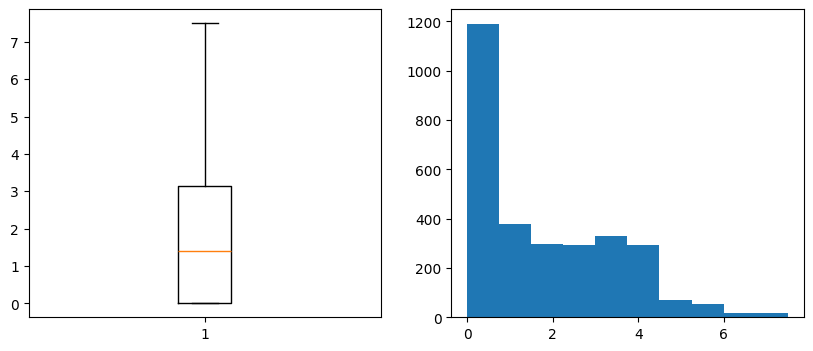

In [131]:
morInf = df['mortesInfantisTransformacaoLog']
fig, axes = plt.subplots(1,2, figsize=(10,4))
axes[0].boxplot(morInf)
axes[1].hist(morInf)

In [132]:
# agora que a variavel de mortalidade infantil sofreu uma transformacao, vou aplicar uma funçao de normalizaçao para melhorar a distribuiçao dos dados
# vou utilizar a técnica zScore para visualizar os dados em uma escala de desvios padrao

df['mortesInfantisNormalizadaZScore'] = zscore(df['mortesInfantisTransformacaoLog'])


(array([1189.,  378.,  296.,  295.,  329.,  292.,   70.,   53.,   19.,
          16.]),
 array([-1.06365891, -0.61283004, -0.16200117,  0.2888277 ,  0.73965657,
         1.19048543,  1.6413143 ,  2.09214317,  2.54297204,  2.99380091,
         3.44462978]),
 <BarContainer object of 10 artists>)

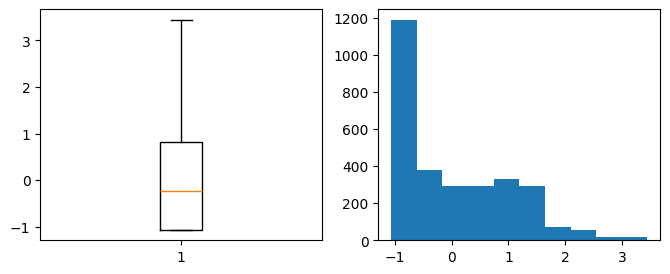

In [174]:
fig, axes = plt.subplots(1,2, figsize=(8,3))
axes[0].boxplot(df['mortesInfantisNormalizadaZScore'])
axes[1].hist(df['mortesInfantisNormalizadaZScore'])

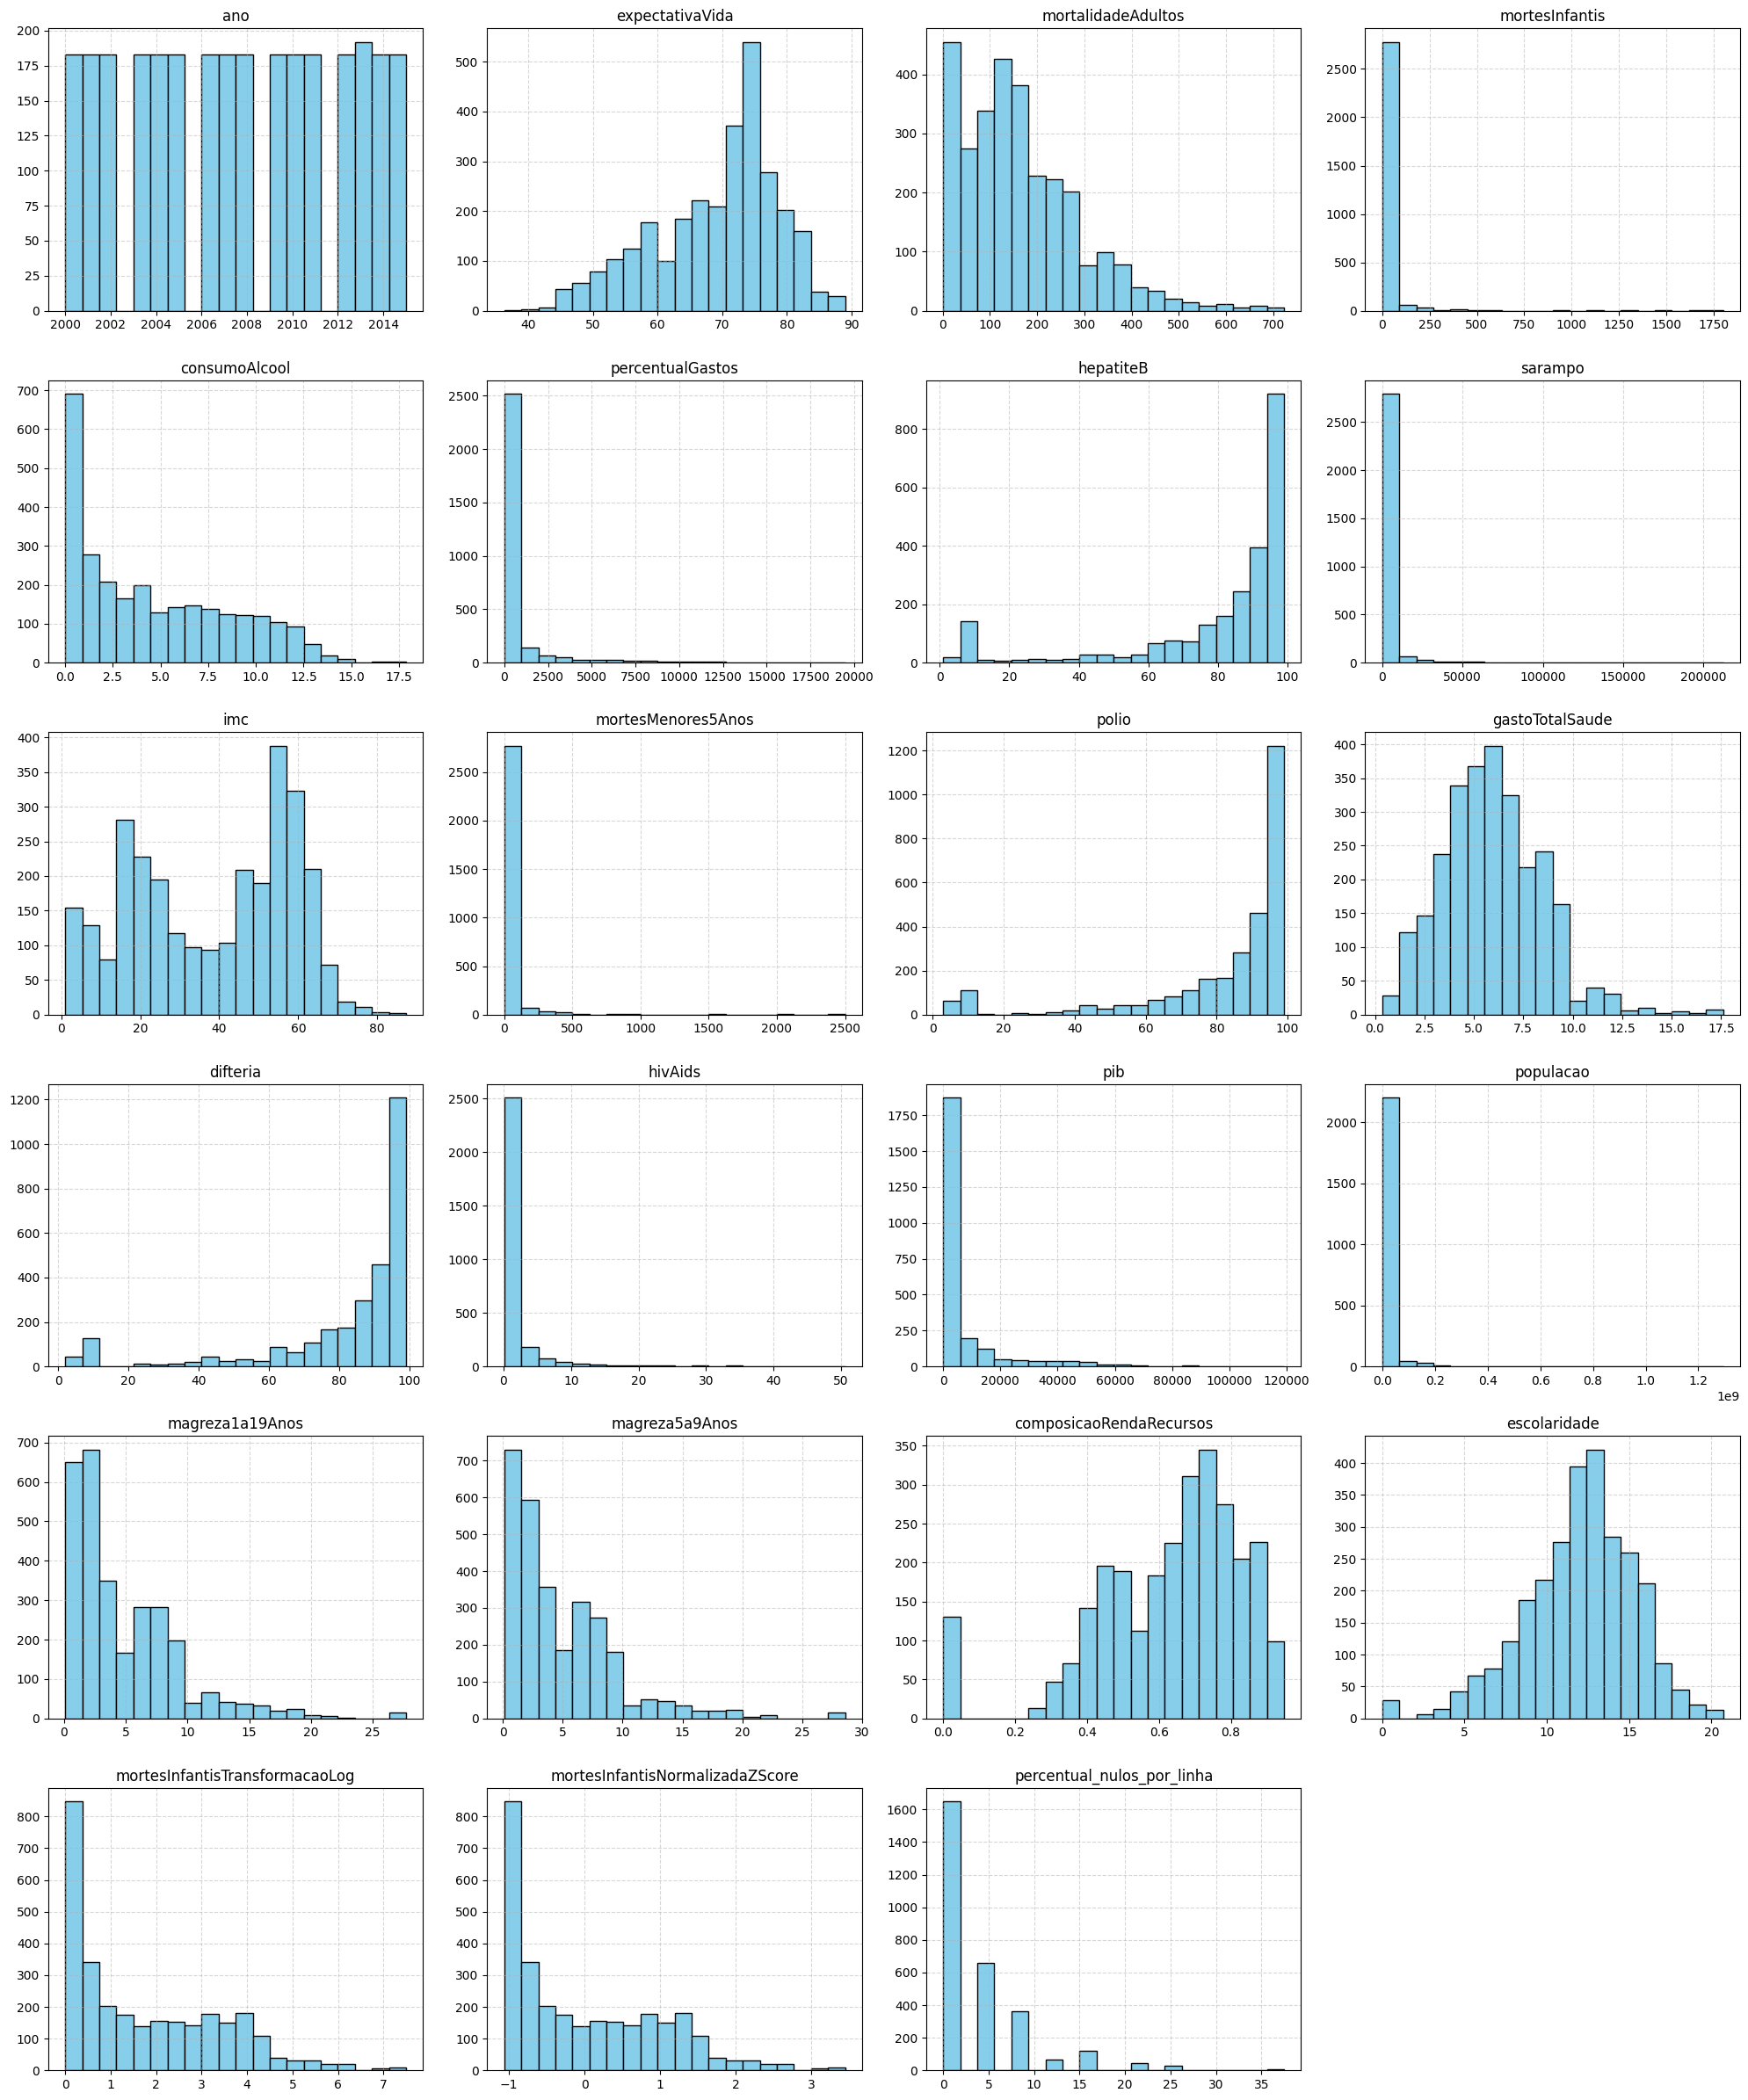

In [173]:
mostraPerfilHistograma()

# fim transformaçao

## Classificação dos Atributos por Tipo de Variável Estatística

- **nmPais (Country)**: Qualitativa Nominal (Nomes de países, sem ordem).
- **ano (Year)**: Quantitativa Discreta (Anos específicos, números inteiros).
- **status (Status)**: Qualitativa Nominal (Desenvolvido/Em desenvolvimento, sem ordem intrínseca).
- **expectativaVida (Life expectancy)**: Quantitativa Contínua (Pode assumir qualquer valor dentro de um intervalo).
- **mortalidadeAdultos (Adult Mortality)**: Quantitativa Contínua (Taxa por 1000, pode ter valores decimais).
- **mortesInfantis (infant deaths)**: Quantitativa Discreta (Número de mortes infantis, contagem).
- **consumoAlcool (Alcohol)**: Quantitativa Contínua (Consumo em litros, pode ter valores decimais).
- **percentualGastos (percentage expenditure)**: Quantitativa Contínua (Percentual, pode ter valores decimais).
- **hepatiteB (Hepatitis B)**: Quantitativa Contínua (Percentual, pode ter valores decimais).
- **sarampo (Measles)**: Quantitativa Discreta (Número de casos de sarampo, contagem).
- **imc (BMI)**: Quantitativa Contínua (Índice de Massa Corporal, pode ter valores decimais).
- **mortesMenores5Anos (under-five deaths)**: Quantitativa Discreta (Número de mortes de menores de cinco anos, contagem).
- **polio (Polio)**: Quantitativa Contínua (Cobertura vacinal em percentual, pode ter valores decimais).
- **gastoTotalSaude (Total expenditure)**: Quantitativa Contínua (Gastos em percentual do PIB, pode ter valores decimais).
- **difteria (Diphtheria)**: Quantitativa Contínua (Cobertura vacinal em percentual, pode ter valores decimais).
- **hivAids (HIV/AIDS)**: Quantitativa Contínua (Mortes por 1000 nascidos vivos, pode ter valores decimais).
- **pib (GDP)**: Quantitativa Contínua (Produto Interno Bruto, pode ter valores decimais).
- **populacao (Population)**: Quantitativa Discreta (Número de pessoas, contagem).
- **magreza1a19Anos (thinness 1-19 years)**: Quantitativa Contínua (Percentual de magreza, pode ter valores decimais).
- **magreza5a9Anos (thinness 5-9 years)**: Quantitativa Contínua (Percentual de magreza, pode ter valores decimais).
- **composicaoRendaRecursos (Income composition of resources)**: Quantitativa Contínua (Índice, pode ter valores decimais).
- **escolaridade (Schooling)**: Quantitativa Contínua (Número de anos de escolaridade, pode ter valores decimais).

In [135]:
linhas_duplicadas = df[df.duplicated()]

if not linhas_duplicadas.empty:
    print(f"Foram encontradas {len(linhas_duplicadas)} linhas duplicadas.")
    display(linhas_duplicadas)
else:
    print("Não foram encontradas linhas duplicadas.")

Não foram encontradas linhas duplicadas.


In [136]:
print("Verificando duplicatas por combinação de 'nmPais' e 'ano'...")
duplicatas_pais_ano = df[df.duplicated(subset=['nmPais', 'ano'], keep=False)]

if not duplicatas_pais_ano.empty:
    print(f"Foram encontradas {len(duplicatas_pais_ano)} linhas com combinações duplicadas de 'nmPais' e 'ano'.")
    display(duplicatas_pais_ano.sort_values(by=['nmPais', 'ano']))
else:
    print("Não foram encontradas combinações duplicadas de 'nmPais' e 'ano'.")

Verificando duplicatas por combinação de 'nmPais' e 'ano'...
Não foram encontradas combinações duplicadas de 'nmPais' e 'ano'.
